In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/firms_fire_data.csv")

df.head()

,latitude,longitude,bright_ti4,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_ti5,frp,daynight
0,30.30019,73.51273,338.00,0.48,0.65,2026-08-12,909,N,VIIRS,n,2.0NRT,290.59,7.14,D
1,31.25882,76.92647,304.80,0.39,0.59,2026-08-12,2133,N,VIIRS,n,2.0NRT,288.82,0.61,N
2,29.34646,73.11682,336.71,0.41,0.37,2026-08-14,833,N,VIIRS,n,2.0NRT,294.38,3.83,D
3,30.65054,73.60814,331.28,0.44,0.38,2026-08-14,833,N,VIIRS,n,2.0NRT,296.58,2.72,D
4,30.89121,73.19951,330.74,0.43,0.38,2026-08-14,833,N,VIIRS,l,2.0NRT,301.34,2.93,D


In [4]:
df.shape

(12, 14)

In [5]:
df.describe()

,latitude,longitude,bright_ti4,scan,track,acq_time,bright_ti5,frp
count,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000
mean,30.739970,73.584053,329.890000,0.430000,0.419167,948.000000,298.558333,3.695000
std,0.493108,1.062509,8.280444,0.020449,0.094720,373.811328,4.787170,1.773422
min,29.346460,73.116820,304.800000,0.390000,0.370000,833.000000,288.820000,0.610000
25%,30.831043,73.203835,330.785000,0.430000,0.380000,833.000000,296.030000,2.930000
50%,30.895595,73.216920,331.125000,0.430000,0.380000,833.000000,301.295000,3.265000
75%,30.908583,73.405750,331.377500,0.430000,0.380000,835.000000,301.517500,3.997500
max,31.258820,76.926470,338.000000,0.480000,0.650000,2133.000000,302.470000,7.140000


In [6]:
df["confidence"].value_counts()

confidence
l    7
n    5
Name: count, dtype: int64

In [7]:
df["daynight"].value_counts()


daynight
D    11
N     1
Name: count, dtype: int64

In [8]:
df["frp"].describe()

count    12.000000
mean      3.695000
std       1.773422
min       0.610000
25%       2.930000
50%       3.265000
75%       3.997500
max       7.140000
Name: frp, dtype: float64

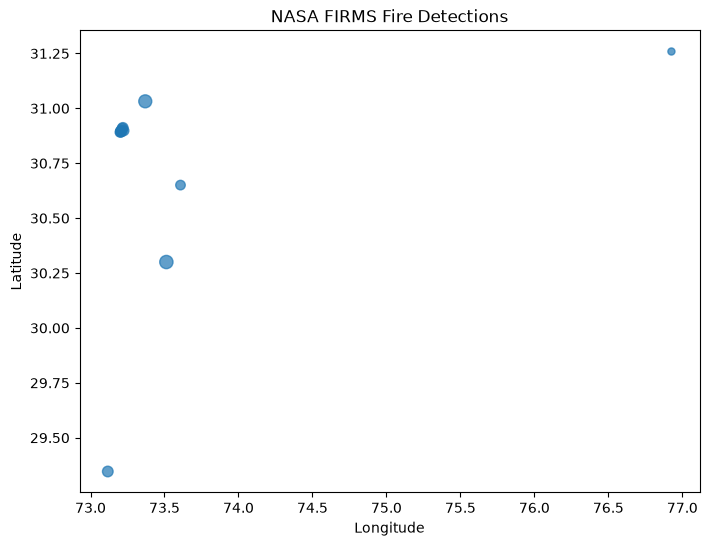

In [9]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["longitude"],
    df["latitude"],
    s=df["frp"] * 10 + 20,
    alpha=0.7
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("NASA FIRMS Fire Detections")

plt.show()

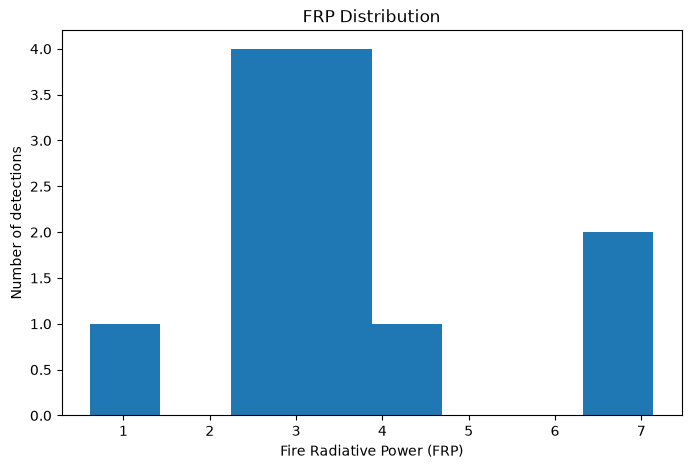

In [10]:
plt.figure(figsize=(8, 5))

plt.hist(df["frp"], bins=8)

plt.xlabel("Fire Radiative Power (FRP)")
plt.ylabel("Number of detections")
plt.title("FRP Distribution")

plt.show()

In [3]:
df["acq_date"].value_counts().sort_index()

acq_date
2026-08-12     2
2026-08-14    10
Name: count, dtype: int64

In [4]:
df["acq_date"] = pd.to_datetime(df["acq_date"])

df["acq_date"].min(), df["acq_date"].max()

(Timestamp('2026-08-12 00:00:00'), Timestamp('2026-08-14 00:00:00'))

In [5]:
df["month"] = df["acq_date"].dt.month
df["day"] = df["acq_date"].dt.day
df["day_of_week"] = df["acq_date"].dt.dayofweek

In [6]:
df[["acq_date", "month", "day", "day_of_week"]]


,acq_date,month,day,day_of_week
0,2026-08-12,8,12,2
1,2026-08-12,8,12,2
2,2026-08-14,8,14,4
3,2026-08-14,8,14,4
4,2026-08-14,8,14,4
5,2026-08-14,8,14,4
6,2026-08-14,8,14,4
7,2026-08-14,8,14,4
8,2026-08-14,8,14,4
9,2026-08-14,8,14,4


In [7]:
numeric_df = df.select_dtypes(include="number")

numeric_df.corr()

,latitude,longitude,bright_ti4,scan,track,acq_time,bright_ti5,frp,month,day,day_of_week
latitude,1.000000,0.336119,-0.547923,-0.142146,0.008083,0.316631,0.330539,-0.283457,NaN,-0.037450,-0.037450
longitude,0.336119,1.000000,-0.936234,-0.534202,0.620857,0.993043,-0.689190,-0.498444,NaN,-0.719018,-0.719018
bright_ti4,-0.547923,-0.936234,1.000000,0.690740,-0.364806,-0.939702,0.400863,0.664064,NaN,0.478920,0.478920
scan,-0.142146,-0.534202,0.690740,1.000000,0.248746,-0.573217,0.050982,0.709914,NaN,-0.114208,-0.114208
track,0.008083,0.620857,-0.364806,0.248746,1.000000,0.614840,-0.832964,0.152048,NaN,-0.990378,-0.990378
acq_time,0.316631,0.993043,-0.939702,-0.573217,0.614840,1.000000,-0.673366,-0.513292,NaN,-0.715997,-0.715997
bright_ti5,0.330539,-0.689190,0.400863,0.050982,-0.832964,-0.673366,1.000000,0.041996,NaN,0.863848,0.863848
frp,-0.283457,-0.498444,0.664064,0.709914,0.152048,-0.513292,0.041996,1.000000,NaN,-0.047410,-0.047410
month,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,-0.037450,-0.719018,0.478920,-0.114208,-0.990378,-0.715997,0.863848,-0.047410,NaN,1.000000,1.000000


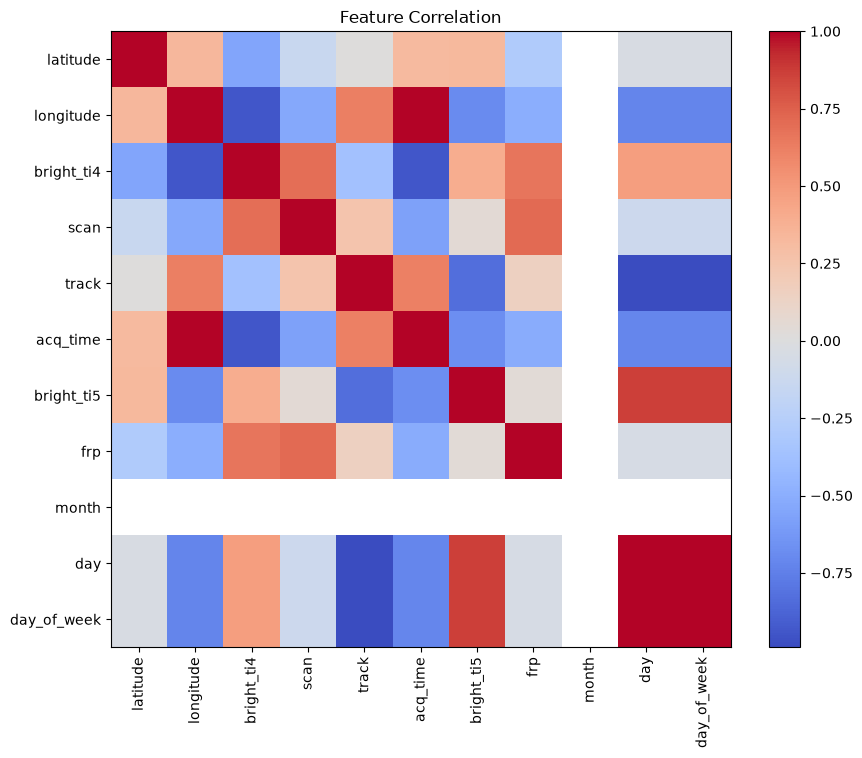

In [8]:
plt.figure(figsize=(10, 8))

plt.imshow(numeric_df.corr(), cmap="coolwarm", aspect="auto")

plt.xticks(
    range(len(numeric_df.columns)),
    numeric_df.columns,
    rotation=90
)

plt.yticks(
    range(len(numeric_df.columns)),
    numeric_df.columns
)

plt.colorbar()

plt.title("Feature Correlation")

plt.show()